In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import polars as pl
import pandas as pd
import multiprocessing as mp
import json

## Data distribution based on fields

In [2]:
def dataStatForField(file):
    """ Generates the total papers based on each fields """
    df = pl.read_parquet(file)
    df_exploded = df.explode('s2fieldsofstudy')
    exploded_list = [i for i in df_exploded["s2fieldsofstudy"]]
    df_sep = pl.from_dicts(exploded_list)
    df_res = df_exploded.with_columns(df_sep)
    df_filter = df_res.filter(pl.col("source") == "external")
    grouped = df_filter.groupby('category')
    newDF = []
    fos = []
    grp = []
        
    for cat, group in grouped:
        newDF.append(group)
        if cat == None:
            cat = "N/A"
        fos.append(cat)
        grp.append(len(group))
            
    return pd.DataFrame({"fields": fos, "count": grp})
    

# # 10819875
# 25627531
# # 12519687

In [3]:
import matplotlib.ticker as mtick

def dataVizForField(df, fileName):
    """ Generates and saves visualization of distribution of fields in the datasets """
    df = df.sort_values(by="count", ascending=False)
    plt.figure(figsize=(17, 12))
    ax = sns.barplot(data=df, x="count", y="fields")
    font_size = 15

    plt.title('Data distribution in different fields',fontsize=font_size)
    # plt.box(on=None)
        # Remove the top and right spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    plt.ylabel('Fields',fontsize=font_size)
            
    for index, value in enumerate(df["count"]):
        plt.text(value, index, f'{value} ({value/df["count"].sum()*100:.2f}%)', ha="left", va="center", color="black",fontsize=font_size)

    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{int(x)}'))
    plt.xlabel('Total Records',fontsize=font_size)
    ax.tick_params(axis='x', labelsize=font_size)
    ax.tick_params(axis='y', labelsize=font_size)
    plt.savefig(fileName)
    plt.show()
    
    plt.close()

#### Data distribution in HuggingFace dataset

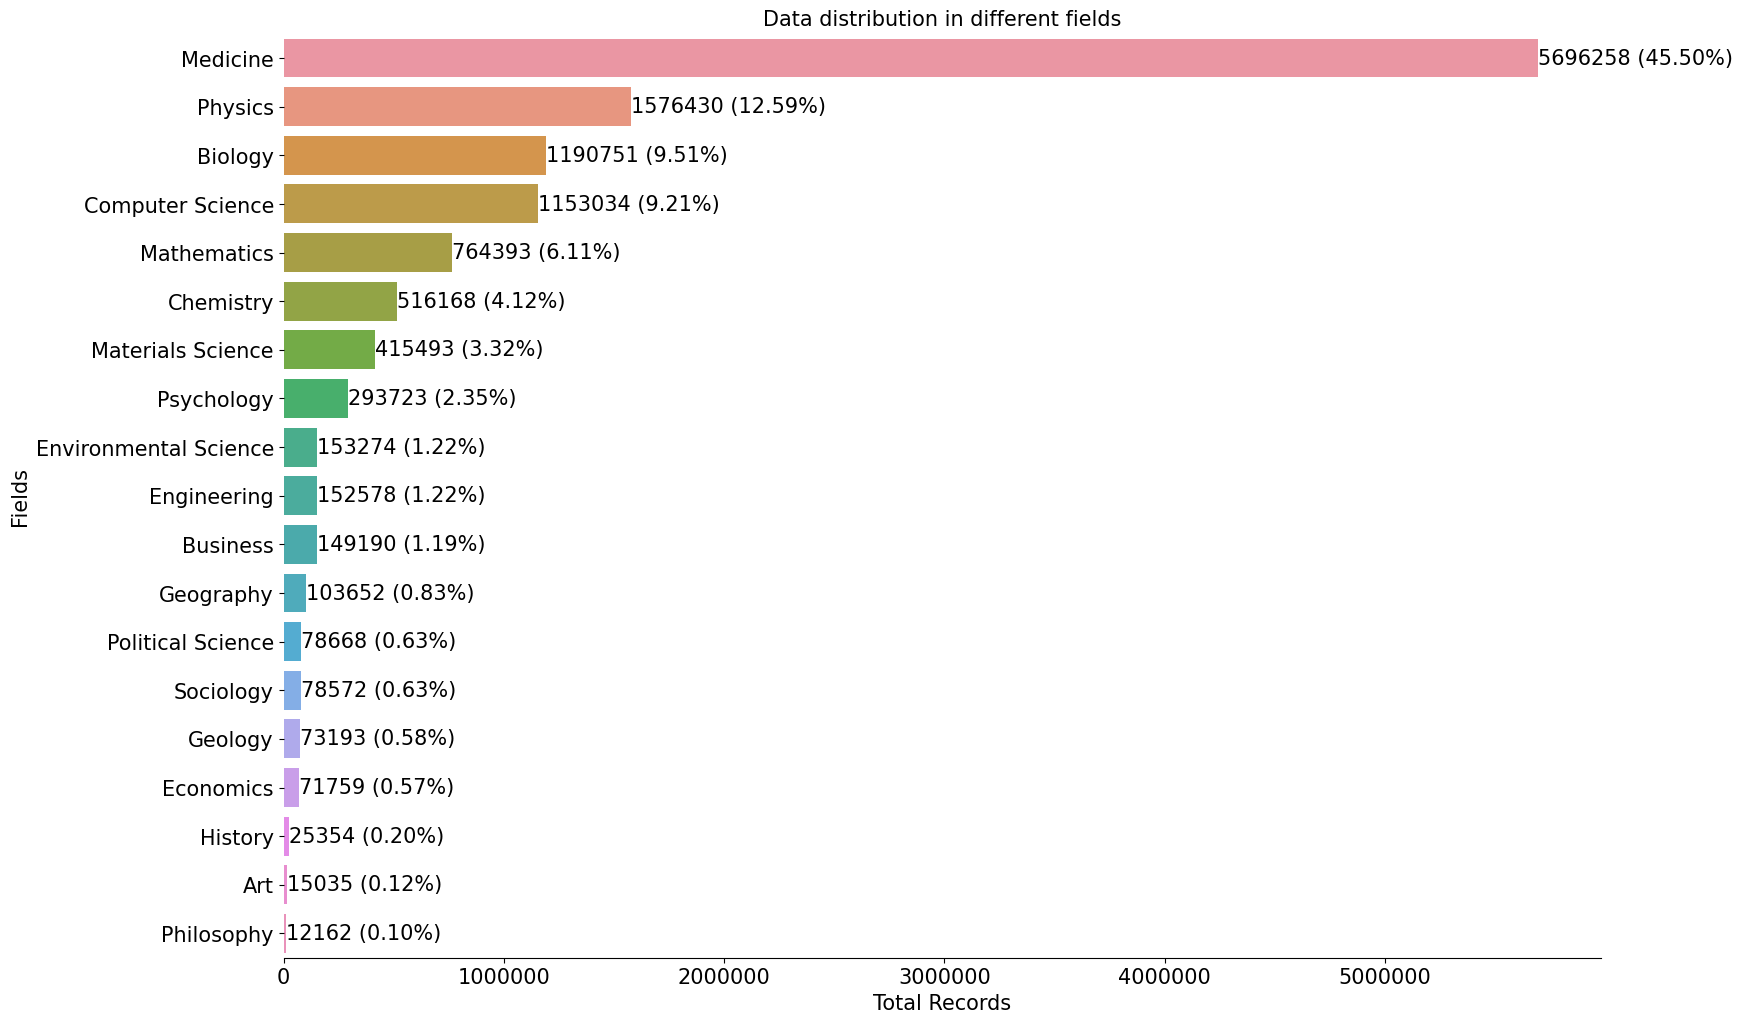

In [5]:
HFStat = dataStatForField("/dataHDD1/pmData/s2orcParsed/combinedPapers.parquet")
dataVizForField(HFStat, "figures/dataDist/dataDistFields.svg")

## Data distribution based on Fields and Years

In [6]:
def dataStatForFieldsAndYear(file):
    """ Generates the total papers based on each fields and years"""
    # df = pl.read_parquet(file)
    # df_exploded = df.explode('fieldOfStudy')
    
    df = pl.read_parquet(file)
    print(len(df))
    df_exploded = df.explode('s2fieldsofstudy')
    print(len(df_exploded))
    exploded_list = [i for i in df_exploded["s2fieldsofstudy"]]
  
    df_sep = pl.from_dicts(exploded_list)
    
    df_res = df_exploded.with_columns(df_sep)
    
    df_filter = df_res.filter(pl.col("source") == "external")
    
    
    grouped = df_filter.groupby(['category',"year"])
    fos = []
    grp = []
    year = []
    
    for ind, group in grouped:
        field = ind[0]
        yr = ind[1]
        if field == None:
            field = "N/A"
        fos.append(field)
        year.append(yr)
        grp.append(len(group))

    return pd.DataFrame({"fields": fos, "count": grp, "year":year}).sort_values(by=["fields","year"])

In [7]:
import matplotlib.cm as cm

def dataVizForFieldAndYear(df, filename):
    """ Generates lineplot to show the paper count for each fields and years (>= 2000 and <= 2023)"""

    df_filtered = df[(df['year'] >= 2000) & (df['year'] <= 2023)]

    # Create a line plot
    plt.figure(figsize=(10, 6))
    
    colors = cm.get_cmap('tab20', len(df_filtered['fields'].unique()))

    # Iterate over unique fields
    for i, field in enumerate(df_filtered['fields'].unique()):
        # Filter the DataFrame for the current field
        field_df = df_filtered[df_filtered['fields'] == field]
        # Plot the line for the current field
        plt.plot(field_df['year'], field_df['count'], label=field, color=colors(i))

    # Set plot title and labels
    plt.title("Count in Each Field Over Time (Years >= 2000 and <= 2023)")
    plt.xlabel("Year")
    plt.ylabel("Count")
    
    plt.xticks(range(2000, 2023, 2))
    
    # Format y-axis tick labels as integers
    plt.gca().get_yaxis().set_major_formatter(mtick.FuncFormatter(lambda x, _: format(int(x), ',')))

    # Move the legend to the upper left of the figure and divide into two columns
    plt.legend(loc='upper left', bbox_to_anchor=(0, 1), ncol=2)
    plt.savefig(filename)

    # Display the plot
    plt.show()


10819875
25627531


/tmp/ipykernel_3039841/3013095657.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = cm.get_cmap('tab20', len(df_filtered['fields'].unique()))


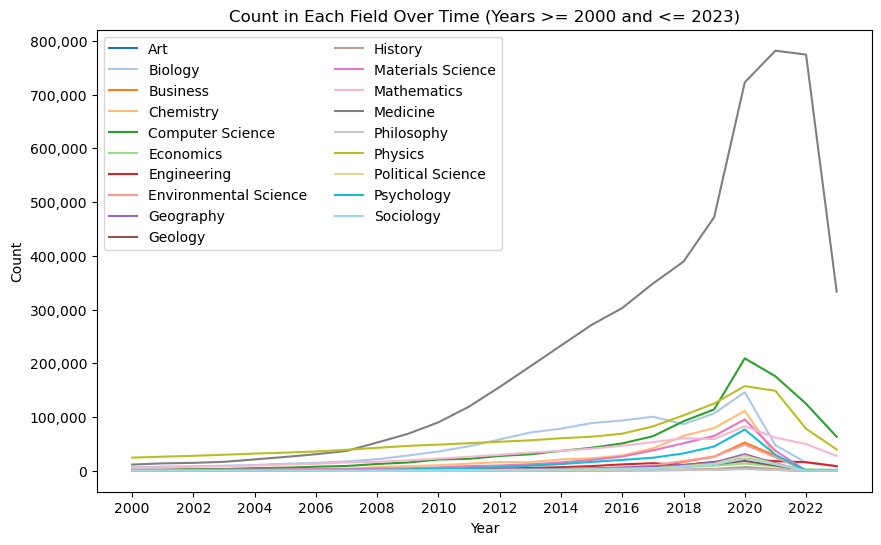

In [8]:
HFStat = dataStatForFieldsAndYear("/dataHDD1/pmData/s2orcParsed/combinedPapers.parquet")
dataVizForFieldAndYear(HFStat,"figures/dataDist/FieldAndYearDistDS.svg")

## Data distribution based on Fields and Citation counts

In [12]:
def dataStatForCitationCount(file):
    """ Generates the total papers based on each fields and normalized citaiton count"""
    
    df = pl.read_parquet(file)
    df_exploded = df.explode('s2fieldsofstudy')
    exploded_list = [i for i in df_exploded["s2fieldsofstudy"]]
  
    df_sep = pl.from_dicts(exploded_list)
    
    df_res = df_exploded.with_columns(df_sep)
    
    df_filter = df_res.filter(pl.col("source") == "external")
    
    
    grouped = df_filter.groupby(['category'])
    fos = []
    grp = []
    normalCitation = []
    
    for ind, group in grouped:
        field = ind[0]
        if field == None:
            field = "N/A"
        fos.append(field)
        grp.append(len(group))
        normalCitation.append(sum(group["citationcount"]) / len(group))
        

    return pd.DataFrame({"fields": fos, "normalCitation":normalCitation}).sort_values(by=["fields", "normalCitation"])

In [20]:
def dataVizForFieldAndCC(df,fileName):
    plt.figure(figsize=(10, 6))
    font_size = 15

    plt.bar(df['fields'], df['normalCitation'],color="skyblue")

    # Set plot title and labels
    plt.title("Nomalized count of citations in fields")
    plt.xlabel("Fields")
    plt.ylabel("Count")
    plt.xticks(rotation='vertical')
    plt.tight_layout()

    
    plt.savefig(fileName)

    # Display the plot
    plt.show()
    


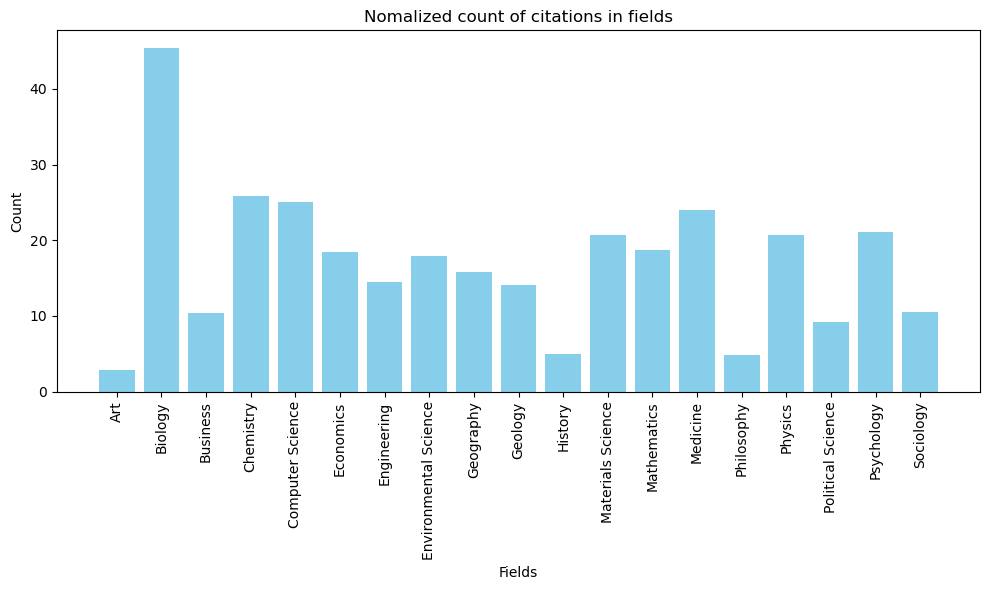

In [21]:
HFStat = dataStatForCitationCount("/dataHDD1/pmData/s2orcParsed/combinedPapers.parquet")

dataVizForFieldAndCC(HFStat,"figures/dataDist/FieldAndCCDistDS.svg")

## Get count for each field for data sampling

In [53]:
combinedStat.sort_values(by="count")

,fields,count
7,History,3082
10,Philosophy,3227
12,Art,3310
9,Political Science,9890
16,Geology,10009
1,Sociology,10266
19,Economics,11776
13,Business,14805
8,Geography,19752
11,Environmental Science,20288


In [54]:
from sklearn.preprocessing import MinMaxScaler,StandardScaler
import numpy as np

# Create a MinMaxScaler instance
scaler = MinMaxScaler()
scaler = StandardScaler()

# Apply min-max normalization to the 'count' column
# combinedStat['normalized_count'] = scaler.fit_transform(combinedStat[['count']])
# combinedStat['normalized_count1'] = scaler.fit_transform(combinedStat[['count']])
combinedStat['normalized_count2'] = np.log(combinedStat['count'])


# Display the normalized DataFrame
print(combinedStat)

                   fields    count  normalized_count2
0       Materials Science    94539          11.456768
1               Sociology    10266           9.236593
2                     N/A    55647          10.926783
3                 Physics   474963          13.070992
4               Chemistry   180230          12.101989
5              Psychology    90979          11.418384
6             Mathematics   307596          12.636543
7                 History     3082           8.033334
8               Geography    19752           9.891010
9       Political Science     9890           9.199279
10             Philosophy     3227           8.079308
11  Environmental Science    20288           9.917785
12                    Art     3310           8.104703
13               Business    14805           9.602720
14            Engineering    27605          10.225752
15               Medicine  1794617          14.400302
16                Geology    10009           9.211240
17                Biology   

## Filter data for 5 years

In [69]:
def dataStatFieldFiveYrs(file):
    """ Generates the total papers based on each fields """
    df = pl.scan_parquet(file).filter(pl.col("year").is_between(2015, 2020)).collect()
    # df = df[(df['year'] >2015) & (df['year'] <= 2020)]

    df_exploded = df.explode('fieldOfStudy')
    grouped = df_exploded.groupby('fieldOfStudy')
    newDF = []
    fos = []
    grp = []
        
    for fieldOfStudy, group in grouped:
        newDF.append(group)
        if fieldOfStudy == None:
            fieldOfStudy = "N/A"
        fos.append(fieldOfStudy)
        grp.append(len(group))
            
    return pd.DataFrame({"fields": fos, "count": grp})


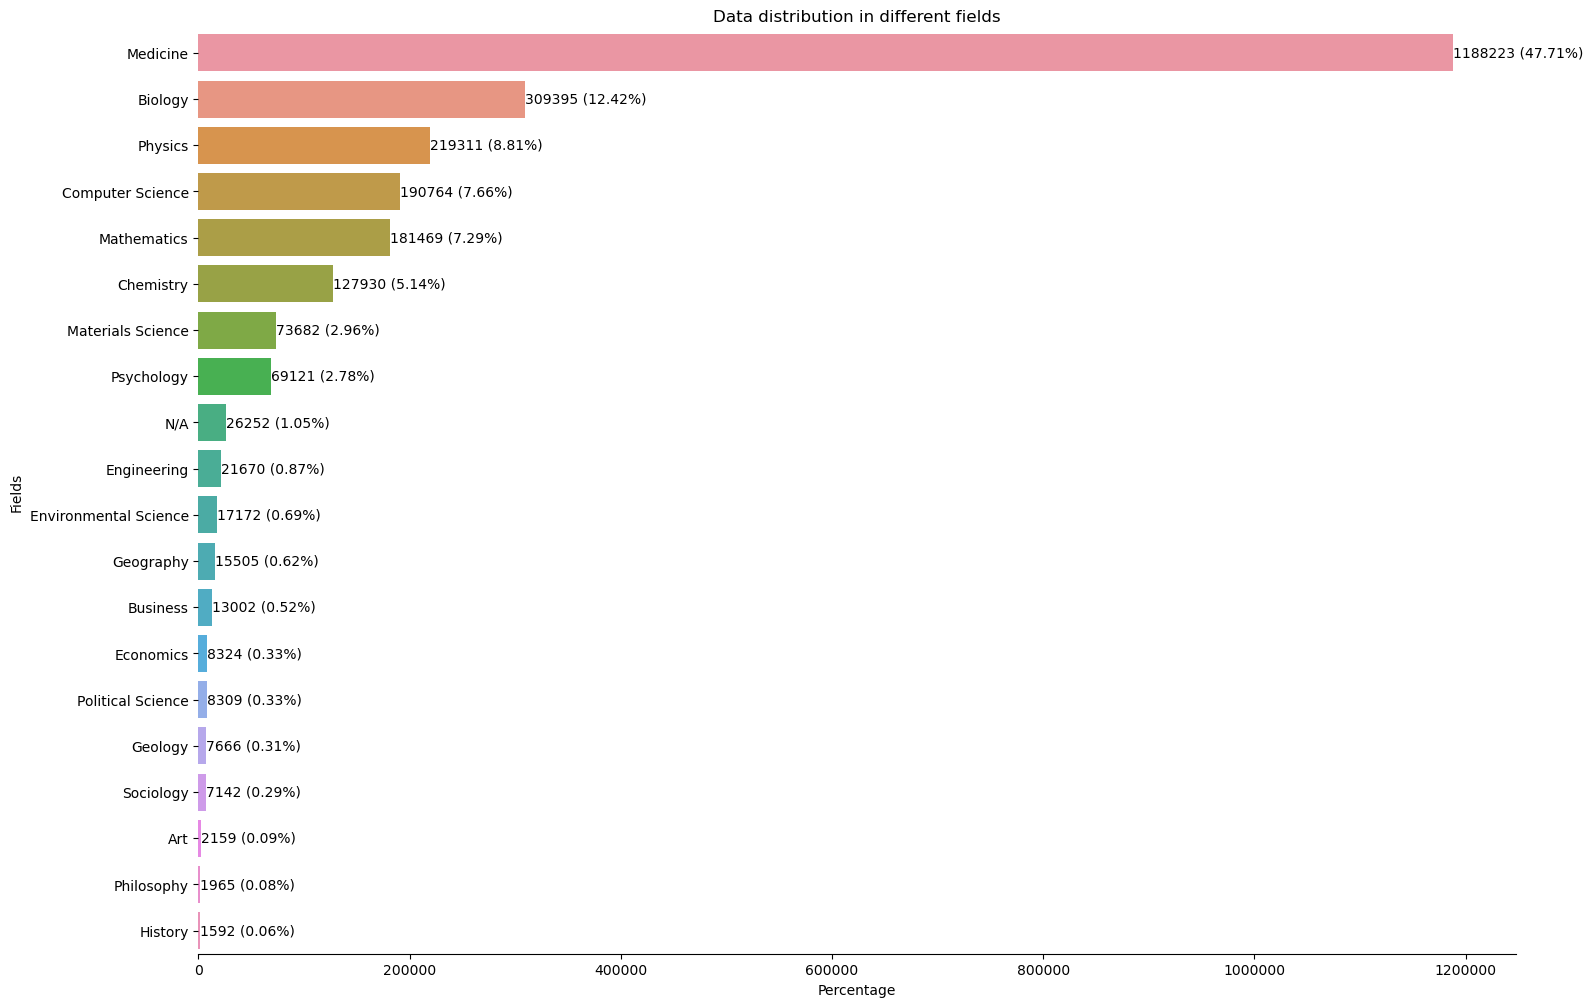

In [70]:
CombinedStatFive = dataStatFieldFiveYrs("/dataHDD1/pmData/s2orcParsed/combinedDS.parquet")
dataVizForField(CombinedStatFive, "figures/FieldDistCombinedDSFive.svg")

In [57]:
import pandas as pd
import random

# Create a DataFrame with the provided data
data = {
    'fields': [
        'History', 'Philosophy', 'Art', 'Political Science', 'Geology',
        'Sociology', 'Economics', 'Business', 'Geography', 'Environmental Science',
        'Engineering', 'N/A', 'Psychology', 'Materials Science', 'Chemistry',
        'Computer Science', 'Mathematics', 'Physics', 'Biology', 'Medicine'
    ],
    'count': [
        3082, 3227, 3310, 9890, 10009, 10266, 11776, 14805, 19752, 20288,
        27605, 55647, 90979, 94539, 180230, 286376, 307596, 474963, 538346, 1794617
    ]
}

df = pd.DataFrame(data)

# Normalize the count column using min-max scaling
min_count = df['count'].min()
max_count = df['count'].max()
df['normalized_count'] = (df['count'] - min_count) / (max_count - min_count)

# Calculate the target counts for each field based on the desired total
target_total = 5000
total_count = df['count'].sum()
df['target_count'] = (df['count'] / total_count) * target_total

# Round the target counts to the nearest whole number
df['target_count'] = df['target_count'].round().astype(int)

# Sample records from each field based on the target counts
sampled_records = []
for index, row in df.iterrows():
    field = row['fields']
    target_count = row['target_count']
    sampled_records.append((field, target_count))

# Calculate the remaining number of records needed to reach the desired total
current_total = sum(record[1] for record in sampled_records)
remaining_total = target_total - current_total

# Randomly sample the remaining records until the desired total is reached
while remaining_total > 0:
    sample = random.choices(df['fields'], weights=df['normalized_count'])[0]
    sample_count = df.loc[df['fields'] == sample, 'count'].values[0]

    if sample_count <= remaining_total:
        sampled_records.append((sample, sample_count))
        remaining_total -= sample_count

# Display the sampled records
print("Sampled Records:")
for record in sampled_records:
    print(f"{record[0]}: {record[1]}")

print(f"Total: {target_total}")

Sampled Records:
History: 4
Philosophy: 4
Art: 4
Political Science: 12
Geology: 13
Sociology: 13
Economics: 15
Business: 19
Geography: 25
Environmental Science: 26
Engineering: 35
N/A: 70
Psychology: 115
Materials Science: 119
Chemistry: 228
Computer Science: 362
Mathematics: 389
Physics: 600
Biology: 680
Medicine: 2267
Total: 5000


## Total files in s3 files:

In [58]:
import polars as pl
for i in range(30):
    df = pl.read_parquet("/dataHDD1/pmData/s2orcDownloads/" + str(i) + ".parquet")
    print(str(i), len(df))


0 353132
1 361291
2 340074
3 384004
4 340162
5 344717
6 342935
7 342309
8 344301
9 344301
10 344358
11 368954
12 346003
13 333676
14 343573
15 356827
16 344404
17 345062
18 339227
19 376143
20 343578
21 343789
22 372617
23 340330
24 336431
25 342606
26 363533
27 364249
28 344007
29 341233


In [59]:
countList = [353132, 361291, 340074, 384004, 340162, 344717, 342935, 342309, 344301, 344301, 344358, 368954, 346003, 333676, 343573, 356827, 344404, 345062, 339227, 376143, 343578, 343789, 372617, 340330, 336431, 342606, 363533, 364249, 344007, 341233]
x = sum(countList)
x

10487826